# Notebook 2 - Logistic Regression

Objective: train and evaluate the Logistic Regression churn model using only the refactored preprocessing pipeline outputs from `run_pipeline(force_ingestion=False, use_database=False)`.

Scope rules for this notebook:

- Use only `outputs['logistic']` for model training and evaluation.
- Use validation data for Threshold Sensitivity Analysis and threshold selection.
- Use test data only after the threshold has been selected from validation data.
- Save tables to `churn_pipeline_v2/reports/data_reports/`.
- Save figures to `churn_pipeline_v2/reports/figures/`.

## 1. Imports

In [1]:
from __future__ import annotations

import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

warnings.filterwarnings('default')
pd.set_option('display.max_columns', 120)
pd.set_option('display.max_rows', 120)

RANDOM_STATE = 42
DEFAULT_THRESHOLD = 0.50
TARGET_RECALL = 0.85
THRESHOLDS = np.round(np.arange(0.05, 0.951, 0.01), 2)


## 2. Path and Folder Checks

In [2]:
def find_refactor_root(start_path: Path) -> Path:
    candidates = [start_path, *start_path.parents]
    for candidate in candidates:
        direct_match = candidate.name == 'churn_pipeline_v2' and (candidate / 'src' / 'main.py').exists()
        nested_match = (candidate / 'churn_pipeline_v2' / 'src' / 'main.py').exists()
        if direct_match:
            return candidate
        if nested_match:
            return candidate / 'churn_pipeline_v2'
    raise FileNotFoundError('Could not locate churn_pipeline_v2 refactor root from current working directory.')


CURRENT_WORKING_DIR = Path.cwd().resolve()
REFACTOR_ROOT = find_refactor_root(CURRENT_WORKING_DIR)
REPO_ROOT = REFACTOR_ROOT.parent
TARGET_NOTEBOOK_PATH = REFACTOR_ROOT / 'notebooks' / '02_Logistic_Regression.ipynb'
LEGACY_NOTEBOOK_PATH = REPO_ROOT / 'notebooks' / '02_Logistic_Regression.ipynb'

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

print('Current working directory:', CURRENT_WORKING_DIR)
print('Refactor project root:', REFACTOR_ROOT)
print('Target notebook path:', TARGET_NOTEBOOK_PATH)
print('Legacy root notebook path:', LEGACY_NOTEBOOK_PATH)
print('Legacy root notebook exists:', LEGACY_NOTEBOOK_PATH.exists())

from churn_pipeline_v2.src.path import (
    DATA_REPORTS_DIR,
    FIGURES_DIR,
    MODELS_DIR,
    NOTEBOOKS_DIR,
    PROJECT_ROOT,
    REPORTS_DIR,
    TEST_DATA_FILE,
    TRAIN_DATA_FILE,
    VALIDATION_DATA_FILE,
)
from churn_pipeline_v2.src.utils.feature_display import (
    build_feature_mapping_table,
    build_feature_reference_table,
    get_category_display_name,
)

path_checks = pd.DataFrame(
    [
        {'name': 'PROJECT_ROOT', 'path': PROJECT_ROOT, 'exists': PROJECT_ROOT.exists(), 'type': 'directory'},
        {'name': 'NOTEBOOKS_DIR', 'path': NOTEBOOKS_DIR, 'exists': NOTEBOOKS_DIR.exists(), 'type': 'directory'},
        {'name': 'REPORTS_DIR', 'path': REPORTS_DIR, 'exists': REPORTS_DIR.exists(), 'type': 'directory'},
        {'name': 'DATA_REPORTS_DIR', 'path': DATA_REPORTS_DIR, 'exists': DATA_REPORTS_DIR.exists(), 'type': 'directory'},
        {'name': 'FIGURES_DIR', 'path': FIGURES_DIR, 'exists': FIGURES_DIR.exists(), 'type': 'directory'},
        {'name': 'MODELS_DIR', 'path': MODELS_DIR, 'exists': MODELS_DIR.exists(), 'type': 'directory'},
        {'name': 'TRAIN_DATA_FILE', 'path': TRAIN_DATA_FILE, 'exists': TRAIN_DATA_FILE.exists(), 'type': 'checkpoint file'},
        {'name': 'VALIDATION_DATA_FILE', 'path': VALIDATION_DATA_FILE, 'exists': VALIDATION_DATA_FILE.exists(), 'type': 'checkpoint file'},
        {'name': 'TEST_DATA_FILE', 'path': TEST_DATA_FILE, 'exists': TEST_DATA_FILE.exists(), 'type': 'checkpoint file'},
    ]
)
path_checks['path'] = path_checks['path'].astype(str)
display(path_checks)

missing_required_dirs = path_checks[(path_checks['type'] == 'directory') & (~path_checks['exists'])]
missing_checkpoints = path_checks[(path_checks['type'] == 'checkpoint file') & (~path_checks['exists'])]

if not missing_required_dirs.empty:
    raise FileNotFoundError(f'Missing required refactor directories: {missing_required_dirs["path"].tolist()}')

if not missing_checkpoints.empty:
    raise FileNotFoundError(
        'Missing checkpoint files. Stopping before run_pipeline() so ingestion is not triggered: '
        f'{missing_checkpoints["path"].tolist()}'
    )

print('All required folders and checkpoint files exist. Safe to call run_pipeline without ingestion.')


Current working directory: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\notebooks
Refactor project root: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2
Target notebook path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\notebooks\02_Logistic_Regression.ipynb
Legacy root notebook path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\notebooks\02_Logistic_Regression.ipynb
Legacy root notebook exists: True


,name,path,exists,type
0,PROJECT_ROOT,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,directory
1,NOTEBOOKS_DIR,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,directory
2,REPORTS_DIR,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,directory
3,DATA_REPORTS_DIR,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,directory
4,FIGURES_DIR,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,directory
5,MODELS_DIR,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,directory
6,TRAIN_DATA_FILE,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,checkpoint file
7,VALIDATION_DATA_FILE,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,checkpoint file
8,TEST_DATA_FILE,D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_G...,True,checkpoint file


All required folders and checkpoint files exist. Safe to call run_pipeline without ingestion.


## 3. Notebook-Local Helpers

In [3]:
def display_and_save_table(df: pd.DataFrame, filename: str, description: str | None = None) -> Path:
    output_path = DATA_REPORTS_DIR / filename
    DATA_REPORTS_DIR.mkdir(parents=True, exist_ok=True)
    if description:
        print(description)
    display(df)
    df.to_csv(output_path, index=False)
    print('Table shape:', df.shape)
    print('Saved table:', output_path)
    return output_path


def save_current_figure(filename: str) -> Path:
    output_path = FIGURES_DIR / filename
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print('Saved figure:', output_path)
    plt.show()
    return output_path


def evaluate_binary_classifier(
    y_true: pd.Series | np.ndarray,
    y_proba: np.ndarray,
    threshold: float,
    model_name: str = 'Logistic Regression',
    split_name: str = 'validation',
) -> pd.DataFrame:
    y_true_array = np.asarray(y_true).astype(int)
    y_pred = (np.asarray(y_proba) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true_array, y_pred, labels=[0, 1]).ravel()
    fpr = fp / (fp + tn) if (fp + tn) else np.nan
    fnr = fn / (fn + tp) if (fn + tp) else np.nan
    unique_classes = np.unique(y_true_array)
    roc_auc = roc_auc_score(y_true_array, y_proba) if len(unique_classes) == 2 else np.nan
    pr_auc = average_precision_score(y_true_array, y_proba) if len(unique_classes) == 2 else np.nan

    return pd.DataFrame(
        [
            {
                'Model': model_name,
                'Split': split_name,
                'Threshold': float(threshold),
                'Accuracy': accuracy_score(y_true_array, y_pred),
                'Precision': precision_score(y_true_array, y_pred, zero_division=0),
                'Recall': recall_score(y_true_array, y_pred, zero_division=0),
                'F1_Score': f1_score(y_true_array, y_pred, zero_division=0),
                'ROC_AUC': roc_auc,
                'PR_AUC': pr_auc,
                'TP': int(tp),
                'FP': int(fp),
                'TN': int(tn),
                'FN': int(fn),
                'False_Positive_Rate': fpr,
                'False_Negative_Rate': fnr,
            }
        ]
    )


def build_confusion_matrix_table(
    y_true: pd.Series | np.ndarray,
    y_pred: np.ndarray,
    split_name: str,
    threshold: float,
) -> pd.DataFrame:
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return pd.DataFrame(
        [
            {'Split': split_name, 'Threshold': threshold, 'Actual': 0, 'Predicted': 0, 'Count': int(tn)},
            {'Split': split_name, 'Threshold': threshold, 'Actual': 0, 'Predicted': 1, 'Count': int(fp)},
            {'Split': split_name, 'Threshold': threshold, 'Actual': 1, 'Predicted': 0, 'Count': int(fn)},
            {'Split': split_name, 'Threshold': threshold, 'Actual': 1, 'Predicted': 1, 'Count': int(tp)},
        ]
    )


def build_classification_report_table(
    y_true: pd.Series | np.ndarray,
    y_pred: np.ndarray,
    split_name: str,
    threshold: float,
) -> pd.DataFrame:
    report = classification_report(y_true, y_pred, labels=[0, 1], output_dict=True, zero_division=0)
    report_df = pd.DataFrame(report).T.reset_index().rename(columns={'index': 'Class'})
    report_df.insert(0, 'Split', split_name)
    report_df.insert(1, 'Threshold', threshold)
    return report_df


def scan_thresholds(
    y_true: pd.Series | np.ndarray,
    y_proba: np.ndarray,
    thresholds: np.ndarray,
    target_recall: float = TARGET_RECALL,
) -> pd.DataFrame:
    rows = []
    for threshold in thresholds:
        metrics = evaluate_binary_classifier(
            y_true=y_true,
            y_proba=y_proba,
            threshold=float(threshold),
            split_name='validation',
        ).iloc[0].to_dict()
        metrics['Meets_Recall_Target'] = metrics['Recall'] >= target_recall
        rows.append(metrics)
    return pd.DataFrame(rows)


def select_threshold(
    threshold_df: pd.DataFrame,
    target_recall: float = TARGET_RECALL,
    close_f1_tolerance: float = 0.001,
) -> tuple[float, pd.DataFrame]:
    candidates = threshold_df[threshold_df['Recall'] >= target_recall].copy()
    if not candidates.empty:
        best_f1 = candidates['F1_Score'].max()
        near_best = candidates[candidates['F1_Score'] >= best_f1 - close_f1_tolerance].copy()
        selected = near_best.sort_values(
            ['Precision', 'F1_Score', 'Threshold'],
            ascending=[False, False, False],
        ).iloc[0]
        target_met = True
        rule = 'Recall target met; selected highest F1-score, with near ties resolved by higher precision.'
    else:
        selected = threshold_df.sort_values(
            ['Recall', 'F1_Score', 'Precision'],
            ascending=[False, False, False],
        ).iloc[0]
        target_met = False
        rule = 'Recall target not met; selected highest recall, then highest F1-score and precision.'

    selected_df = selected.to_frame().T.reset_index(drop=True)
    selected_df['Target_Recall'] = target_recall
    selected_df['Recall_Target_Met'] = target_met
    selected_df['Selection_Rule'] = rule
    return float(selected['Threshold']), selected_df


def plot_confusion_matrix_from_values(
    y_true: pd.Series | np.ndarray,
    y_pred: np.ndarray,
    title: str,
) -> None:
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(6, 5))
    image = ax.imshow(cm, interpolation='nearest', cmap='Blues')
    ax.figure.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(title)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('Actual label')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels([get_category_display_name('Churn', 0), get_category_display_name('Churn', 1)])
    ax.set_yticklabels([get_category_display_name('Churn', 0), get_category_display_name('Churn', 1)])
    threshold_value = cm.max() / 2 if cm.size else 0
    for row_index in range(cm.shape[0]):
        for col_index in range(cm.shape[1]):
            color = 'white' if cm[row_index, col_index] > threshold_value else 'black'
            ax.text(col_index, row_index, int(cm[row_index, col_index]), ha='center', va='center', color=color)


def plot_threshold_sensitivity(threshold_df: pd.DataFrame, selected_threshold: float) -> None:
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(threshold_df['Threshold'], threshold_df['Precision'], label='Precision', linewidth=2)
    ax.plot(threshold_df['Threshold'], threshold_df['Recall'], label='Recall', linewidth=2)
    ax.plot(threshold_df['Threshold'], threshold_df['F1_Score'], label='F1-score', linewidth=2)
    ax.axhline(TARGET_RECALL, color='gray', linestyle='--', linewidth=1.5, label=f'Target recall {TARGET_RECALL:.2f}')
    ax.axvline(selected_threshold, color='black', linestyle=':', linewidth=1.8, label=f'Selected threshold {selected_threshold:.2f}')
    ax.set_title('Threshold Sensitivity Analysis - Validation')
    ax.set_xlabel('Threshold')
    ax.set_ylabel('Score')
    ax.set_xlim(0.05, 0.95)
    ax.set_ylim(0.0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend(loc='best')


def plot_roc_curve(y_true: pd.Series | np.ndarray, y_proba: np.ndarray) -> None:
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    roc_auc = roc_auc_score(y_true, y_proba)
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot(fpr, tpr, linewidth=2, label=f'ROC-AUC = {roc_auc:.4f}')
    ax.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.5)
    ax.set_title('ROC Curve - Validation')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.grid(alpha=0.3)
    ax.legend(loc='lower right')


def plot_precision_recall_curve(y_true: pd.Series | np.ndarray, y_proba: np.ndarray) -> None:
    precision, recall, _ = precision_recall_curve(y_true, y_proba)
    pr_auc = average_precision_score(y_true, y_proba)
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot(recall, precision, linewidth=2, label=f'PR-AUC = {pr_auc:.4f}')
    ax.set_title('Precision-Recall Curve - Validation')
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_xlim(0.0, 1.0)
    ax.set_ylim(0.0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend(loc='best')


def build_coefficient_table(model: LogisticRegression, feature_names: pd.Index) -> pd.DataFrame:
    mapping_df = build_feature_mapping_table(feature_names)
    mapping_df['Coefficient'] = model.coef_[0]
    mapping_df['Abs_Coefficient'] = mapping_df['Coefficient'].abs()
    mapping_df['Direction'] = np.select(
        [mapping_df['Coefficient'] > 0, mapping_df['Coefficient'] < 0],
        ['increases churn probability', 'decreases churn probability'],
        default='no directional effect',
    )

    # Backward-compatible aliases for earlier report consumers.
    mapping_df['feature'] = mapping_df['Feature_Code']
    mapping_df['coefficient'] = mapping_df['Coefficient']
    mapping_df['abs_coefficient'] = mapping_df['Abs_Coefficient']
    mapping_df['direction'] = mapping_df['Direction']

    ordered_columns = [
        'Feature_Code',
        'Feature_Display_Name',
        'Base_Feature',
        'Base_Feature_Display_Name',
        'Encoded_Category',
        'Encoded_Category_Display_Name',
        'Feature_Group',
        'Feature_Type',
        'Is_Encoded',
        'Coefficient',
        'Abs_Coefficient',
        'Direction',
        'feature',
        'coefficient',
        'abs_coefficient',
        'direction',
    ]
    return mapping_df[ordered_columns].sort_values('Abs_Coefficient', ascending=False).reset_index(drop=True)


def plot_coefficient_barh(coefficient_df: pd.DataFrame, title: str, value_column: str = 'Coefficient') -> None:
    fig, ax = plt.subplots(figsize=(10, 6))
    plot_df = coefficient_df.iloc[::-1].copy()
    coefficient_column = 'Coefficient' if 'Coefficient' in plot_df.columns else 'coefficient'
    label_column = 'Feature_Display_Name' if 'Feature_Display_Name' in plot_df.columns else 'feature'
    colors = np.where(plot_df[coefficient_column] >= 0, '#b83232', '#2f6f9f')
    ax.barh(plot_df[label_column], plot_df[value_column], color=colors)
    ax.axvline(0, color='black', linewidth=1)
    ax.set_title(title)
    ax.set_xlabel(value_column.replace('_', ' ').title())
    ax.set_ylabel('Feature')
    ax.grid(axis='x', alpha=0.25)


## 4. Load Preprocessing Outputs Using `run_pipeline()`

In [4]:
from churn_pipeline_v2.src.main import run_pipeline

result = run_pipeline(force_ingestion=False, use_database=False)
builder = result['builder']
outputs = result['outputs']

logistic_train = outputs['logistic']['train']
logistic_val = outputs['logistic']['validation']
logistic_test = outputs['logistic']['test']

tree_train = outputs['tree']['train']
tree_val = outputs['tree']['validation']
tree_test = outputs['tree']['test']

print('Logistic branch shapes:')
print('train:', logistic_train.shape)
print('validation:', logistic_val.shape)
print('test:', logistic_test.shape)

print('\nTree branch shapes for comparison only:')
print('train:', tree_train.shape)
print('validation:', tree_val.shape)
print('test:', tree_test.shape)


2026-07-08 11:59:35,909 - main - [INFO] - Refactored churn pipeline orchestration started.
2026-07-08 11:59:35,914 - main - [INFO] - Run options: force_ingestion=False, use_database=False, view_name=None
2026-07-08 11:59:35,915 - main - [INFO] - Train checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\train_df.csv
2026-07-08 11:59:35,915 - main - [INFO] - Validation checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\validation_df.csv
2026-07-08 11:59:35,916 - main - [INFO] - Test checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\test_df.csv
2026-07-08 11:59:35,917 - main - [INFO] - All checkpoint files exist; ingestion skipped.
2026-07-08 11:59:35,931 - main - [INFO] - Loaded train checkpoint shape: (4930, 16)


All required project directories are available.
All required project directories are available.


2026-07-08 11:59:35,932 - main - [INFO] - Loaded validation checkpoint shape: (1056, 16)
2026-07-08 11:59:35,933 - main - [INFO] - Loaded test checkpoint shape: (1057, 16)
2026-07-08 11:59:36,121 - main - [INFO] - Logistic train output shape: (4930, 28)
2026-07-08 11:59:36,121 - main - [INFO] - Logistic validation output shape: (1056, 28)
2026-07-08 11:59:36,121 - main - [INFO] - Logistic test output shape: (1057, 28)
2026-07-08 11:59:36,125 - main - [INFO] - Tree train output shape: (4930, 20)
2026-07-08 11:59:36,125 - main - [INFO] - Tree validation output shape: (1056, 20)
2026-07-08 11:59:36,127 - main - [INFO] - Tree test output shape: (1057, 20)
2026-07-08 11:59:36,127 - main - [INFO] - Preprocessing branch orchestration completed.
2026-07-08 11:59:36,127 - main - [INFO] - Refactored churn pipeline orchestration finished.


Logistic branch shapes:
train: (4930, 28)
validation: (1056, 28)
test: (1057, 28)

Tree branch shapes for comparison only:
train: (4930, 20)
validation: (1056, 20)
test: (1057, 20)


## 5. Logistic Branch Sanity Checks

In [5]:
def display_logistic_branch_checks(name: str, df: pd.DataFrame) -> None:
    print(f'{name} shape:', df.shape)
    print(f'{name} row count:', df.shape[0])
    print(f'{name} column count:', df.shape[1])
    print(f'{name} column names:')
    print(df.columns.tolist())
    print(f'{name} head:')
    display(df.head())

    dtype_summary = df.dtypes.astype(str).value_counts().rename_axis('dtype').reset_index(name='column_count')
    print(f'{name} dtypes summary:')
    display(dtype_summary)

    dtype_detail = df.dtypes.astype(str).rename('dtype').reset_index().rename(columns={'index': 'column'})
    display(dtype_detail)

    print(f'{name} ID exists:', 'ID' in df.columns)
    print(f'{name} Churn exists:', 'Churn' in df.columns)
    if 'ID' not in df.columns or 'Churn' not in df.columns:
        raise ValueError(f'{name} is missing ID or Churn.')

    object_columns = df.select_dtypes(include='object').columns.tolist()
    unexpected_object_columns = [column for column in object_columns if column != 'ID']
    print(f'{name} object columns:', object_columns)
    print(f'{name} only expected object column is ID:', len(unexpected_object_columns) == 0)
    if unexpected_object_columns:
        raise TypeError(f'{name} has unexpected object columns: {unexpected_object_columns}')

    missing_summary = df.isna().sum().rename('missing_count').reset_index().rename(columns={'index': 'column'})
    missing_summary['missing_rate'] = missing_summary['missing_count'] / len(df)
    print(f'{name} missing values summary:')
    display(missing_summary)
    print(f'{name} total missing values:', int(missing_summary['missing_count'].sum()))

    churn_distribution = df['Churn'].value_counts(dropna=False).rename_axis('Churn').reset_index(name='count')
    churn_distribution['share'] = churn_distribution['count'] / churn_distribution['count'].sum()
    print(f'{name} Churn class distribution:')
    display(churn_distribution)


for split_name, split_df in {
    'logistic_train': logistic_train,
    'logistic_validation': logistic_val,
    'logistic_test': logistic_test,
}.items():
    display_logistic_branch_checks(split_name, split_df)


logistic_train shape: (4930, 28)
logistic_train row count: 4930
logistic_train column count: 28
logistic_train column names:
['ID', 'Churn', 'SeniorCitizen', 'Tenure', 'MonthlyCharges', 'TotalCharges', 'service_diversity', 'monthly_charges_ratio', 'is_paperless_electronic', 'Dependents_Yes', 'Contract_12', 'Contract_24', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'InternetService_Fiber optic', 'InternetService_No', 'tenure_group_13-24 months', 'tenure_group_25-36 months', 'tenure_group_37-48 months', 'tenure_group_49-60 months', 'tenure_group_61-72 months', 'Partner_1', 'PaperlessBilling_1', 'OnlineSecurity_1', 'OnlineBackup_1', 'DeviceProtection_1', 'TechSupport_1']
logistic_train head:


,ID,Churn,SeniorCitizen,Tenure,MonthlyCharges,TotalCharges,service_diversity,monthly_charges_ratio,is_paperless_electronic,Dependents_Yes,Contract_12,Contract_24,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,InternetService_Fiber optic,InternetService_No,tenure_group_13-24 months,tenure_group_25-36 months,tenure_group_37-48 months,tenure_group_49-60 months,tenure_group_61-72 months,Partner_1,PaperlessBilling_1,OnlineSecurity_1,OnlineBackup_1,DeviceProtection_1,TechSupport_1
0,7883-ROJOC,0,-0.439133,-0.542089,-0.655880,-0.121630,-0.971554,-0.655880,-0.582816,-0.546567,-0.513594,-0.567825,-0.529013,-0.707968,1.818152,-0.889255,-0.534976,2.396703,-0.363005,-0.345964,-0.367641,-0.499366,1.045241,-1.217016,-0.630705,-0.723523,-0.713463,-0.635735
1,3164-AALRN,1,-0.439133,-1.112649,0.174817,-0.681594,-0.196386,0.174817,-0.582816,-0.546567,1.947064,-0.567825,-0.529013,-0.707968,1.818152,-0.889255,-0.534976,-0.417240,-0.363005,-0.345964,-0.367641,-0.499366,-0.956717,0.821682,-0.630705,-0.723523,1.401614,-0.635735
2,9821-POOTN,1,-0.439133,0.109979,0.346914,0.590564,-0.971554,0.346914,-0.582816,-0.546567,-0.513594,-0.567825,-0.529013,1.412494,-0.550009,1.124537,-0.534976,-0.417240,2.754787,-0.345964,-0.367641,-0.499366,1.045241,0.821682,-0.630705,-0.723523,-0.713463,-0.635735
3,3259-QMXUN,0,-0.439133,1.047326,0.707655,0.997935,1.353949,0.707655,-0.582816,-0.546567,-0.513594,1.761107,-0.529013,1.412494,-0.550009,-0.889255,-0.534976,-0.417240,-0.363005,-0.345964,2.720044,-0.499366,1.045241,0.821682,1.585528,1.382126,1.401614,-0.635735
4,1226-UDFZR,1,-0.439133,-1.234911,-0.500331,-1.382388,-0.196386,-0.500331,-0.582816,-0.546567,-0.513594,-0.567825,-0.529013,-0.707968,1.818152,-0.889255,-0.534976,-0.417240,-0.363005,-0.345964,-0.367641,-0.499366,-0.956717,0.821682,-0.630705,1.382126,-0.713463,-0.635735


logistic_train dtypes summary:


,dtype,column_count
0,float64,26
1,object,1
2,int64,1


,column,dtype
0,ID,object
1,Churn,int64
2,SeniorCitizen,float64
3,Tenure,float64
4,MonthlyCharges,float64
5,TotalCharges,float64
6,service_diversity,float64
7,monthly_charges_ratio,float64
8,is_paperless_electronic,float64
9,Dependents_Yes,float64


logistic_train ID exists: True
logistic_train Churn exists: True
logistic_train object columns: ['ID']
logistic_train only expected object column is ID: True
logistic_train missing values summary:


... (17 outputs left out)

logistic_test ID exists: True
logistic_test Churn exists: True
logistic_test object columns: ['ID']
logistic_test only expected object column is ID: True
logistic_test missing values summary:


,column,missing_count,missing_rate
0,ID,0,0.0
1,Churn,0,0.0
2,SeniorCitizen,0,0.0
3,Tenure,0,0.0
4,MonthlyCharges,0,0.0
5,TotalCharges,0,0.0
6,service_diversity,0,0.0
7,monthly_charges_ratio,0,0.0
8,is_paperless_electronic,0,0.0
9,Dependents_Yes,0,0.0


logistic_test total missing values: 0
logistic_test Churn class distribution:


,Churn,count,share
0,0,776,0.734153
1,1,281,0.265847


## 6. X/y Split

In [6]:
X_train = logistic_train.drop(columns=['ID', 'Churn'])
y_train = logistic_train['Churn'].astype(int)

X_val = logistic_val.drop(columns=['ID', 'Churn'])
y_val = logistic_val['Churn'].astype(int)

X_test = logistic_test.drop(columns=['ID', 'Churn'])
y_test = logistic_test['Churn'].astype(int)

print('X_train.shape:', X_train.shape)
print('X_val.shape:', X_val.shape)
print('X_test.shape:', X_test.shape)
print('y_train.shape:', y_train.shape)
print('y_val.shape:', y_val.shape)
print('y_test.shape:', y_test.shape)

print('ID not in X_train.columns:', 'ID' not in X_train.columns)
print('Churn not in X_train.columns:', 'Churn' not in X_train.columns)
print('ID not in X_val.columns:', 'ID' not in X_val.columns)
print('Churn not in X_val.columns:', 'Churn' not in X_val.columns)
print('ID not in X_test.columns:', 'ID' not in X_test.columns)
print('Churn not in X_test.columns:', 'Churn' not in X_test.columns)

if any(column in X_train.columns for column in ['ID', 'Churn']):
    raise RuntimeError('X_train still contains ID or Churn.')
if any(column in X_val.columns for column in ['ID', 'Churn']):
    raise RuntimeError('X_val still contains ID or Churn.')
if any(column in X_test.columns for column in ['ID', 'Churn']):
    raise RuntimeError('X_test still contains ID or Churn.')

print('X_train head:')
display(X_train.head())

print('y_train value counts:')
display(y_train.value_counts().rename_axis('Churn').reset_index(name='count'))


X_train.shape: (4930, 26)
X_val.shape: (1056, 26)
X_test.shape: (1057, 26)
y_train.shape: (4930,)
y_val.shape: (1056,)
y_test.shape: (1057,)
ID not in X_train.columns: True
Churn not in X_train.columns: True
ID not in X_val.columns: True
Churn not in X_val.columns: True
ID not in X_test.columns: True
Churn not in X_test.columns: True
X_train head:


,SeniorCitizen,Tenure,MonthlyCharges,TotalCharges,service_diversity,monthly_charges_ratio,is_paperless_electronic,Dependents_Yes,Contract_12,Contract_24,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,InternetService_Fiber optic,InternetService_No,tenure_group_13-24 months,tenure_group_25-36 months,tenure_group_37-48 months,tenure_group_49-60 months,tenure_group_61-72 months,Partner_1,PaperlessBilling_1,OnlineSecurity_1,OnlineBackup_1,DeviceProtection_1,TechSupport_1
0,-0.439133,-0.542089,-0.655880,-0.121630,-0.971554,-0.655880,-0.582816,-0.546567,-0.513594,-0.567825,-0.529013,-0.707968,1.818152,-0.889255,-0.534976,2.396703,-0.363005,-0.345964,-0.367641,-0.499366,1.045241,-1.217016,-0.630705,-0.723523,-0.713463,-0.635735
1,-0.439133,-1.112649,0.174817,-0.681594,-0.196386,0.174817,-0.582816,-0.546567,1.947064,-0.567825,-0.529013,-0.707968,1.818152,-0.889255,-0.534976,-0.417240,-0.363005,-0.345964,-0.367641,-0.499366,-0.956717,0.821682,-0.630705,-0.723523,1.401614,-0.635735
2,-0.439133,0.109979,0.346914,0.590564,-0.971554,0.346914,-0.582816,-0.546567,-0.513594,-0.567825,-0.529013,1.412494,-0.550009,1.124537,-0.534976,-0.417240,2.754787,-0.345964,-0.367641,-0.499366,1.045241,0.821682,-0.630705,-0.723523,-0.713463,-0.635735
3,-0.439133,1.047326,0.707655,0.997935,1.353949,0.707655,-0.582816,-0.546567,-0.513594,1.761107,-0.529013,1.412494,-0.550009,-0.889255,-0.534976,-0.417240,-0.363005,-0.345964,2.720044,-0.499366,1.045241,0.821682,1.585528,1.382126,1.401614,-0.635735
4,-0.439133,-1.234911,-0.500331,-1.382388,-0.196386,-0.500331,-0.582816,-0.546567,-0.513594,-0.567825,-0.529013,-0.707968,1.818152,-0.889255,-0.534976,-0.417240,-0.363005,-0.345964,-0.367641,-0.499366,-0.956717,0.821682,-0.630705,1.382126,-0.713463,-0.635735


y_train value counts:


,Churn,count
0,0,3622
1,1,1308


## 7. Train Logistic Regression

In [7]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE,
    class_weight='balanced',
)

logistic_model.fit(X_train, y_train)

validation_proba = logistic_model.predict_proba(X_val)[:, 1]
validation_pred_default = (validation_proba >= DEFAULT_THRESHOLD).astype(int)

print('Baseline Logistic Regression trained.')
print('Validation probability array shape:', validation_proba.shape)
print('Validation default prediction threshold:', DEFAULT_THRESHOLD)


Baseline Logistic Regression trained.
Validation probability array shape: (1056,)
Validation default prediction threshold: 0.5


## 8. Default Validation Evaluation at Threshold 0.50

Validation metrics at default threshold 0.50


,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate
0,Logistic Regression,validation,0.5,0.75947,0.53066,0.803571,0.639205,0.854773,0.665839,225,199,577,55,0.256443,0.196429


Table shape: (1, 15)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\logistic_default_threshold_validation_metrics.csv
Validation confusion matrix table at default threshold 0.50


,Split,Threshold,Actual,Predicted,Count
0,validation,0.5,0,0,577
1,validation,0.5,0,1,199
2,validation,0.5,1,0,55
3,validation,0.5,1,1,225


Table shape: (4, 5)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\logistic_default_threshold_validation_confusion_matrix.csv
Validation classification report at default threshold 0.50


,Split,Threshold,Class,precision,recall,f1-score,support
0,validation,0.5,0,0.912975,0.743557,0.819602,776.00000
1,validation,0.5,1,0.530660,0.803571,0.639205,280.00000
2,validation,0.5,accuracy,0.759470,0.759470,0.759470,0.75947
3,validation,0.5,macro avg,0.721818,0.773564,0.729403,1056.00000
4,validation,0.5,weighted avg,0.811603,0.759470,0.771770,1056.00000


Table shape: (5, 7)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\logistic_default_threshold_validation_classification_report.csv
Classification report at validation threshold 0.50:
              precision    recall  f1-score   support

           0       0.91      0.74      0.82       776
           1       0.53      0.80      0.64       280

    accuracy                           0.76      1056
   macro avg       0.72      0.77      0.73      1056
weighted avg       0.81      0.76      0.77      1056

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\logistic_01_validation_confusion_matrix_default_threshold.png


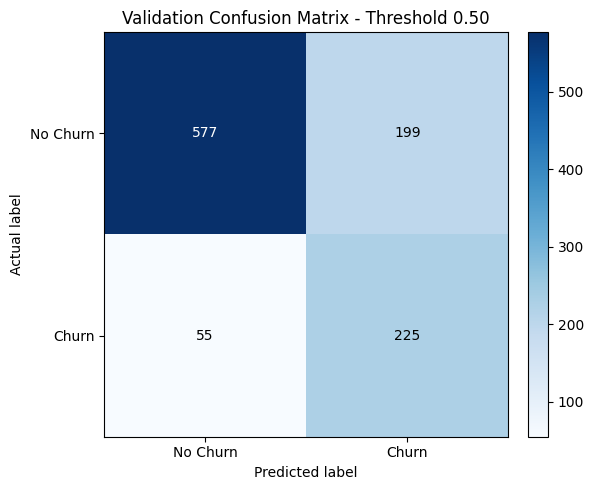

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/logistic_01_validation_confusion_matrix_default_threshold.png')

In [8]:
default_validation_metrics = evaluate_binary_classifier(
    y_true=y_val,
    y_proba=validation_proba,
    threshold=DEFAULT_THRESHOLD,
    split_name='validation',
)
display_and_save_table(
    default_validation_metrics,
    'logistic_default_threshold_validation_metrics.csv',
    'Validation metrics at default threshold 0.50',
)

default_validation_confusion_matrix = build_confusion_matrix_table(
    y_true=y_val,
    y_pred=validation_pred_default,
    split_name='validation',
    threshold=DEFAULT_THRESHOLD,
)
display_and_save_table(
    default_validation_confusion_matrix,
    'logistic_default_threshold_validation_confusion_matrix.csv',
    'Validation confusion matrix table at default threshold 0.50',
)

default_validation_classification_report = build_classification_report_table(
    y_true=y_val,
    y_pred=validation_pred_default,
    split_name='validation',
    threshold=DEFAULT_THRESHOLD,
)
display_and_save_table(
    default_validation_classification_report,
    'logistic_default_threshold_validation_classification_report.csv',
    'Validation classification report at default threshold 0.50',
)

print('Classification report at validation threshold 0.50:')
print(classification_report(y_val, validation_pred_default, zero_division=0))

plot_confusion_matrix_from_values(
    y_true=y_val,
    y_pred=validation_pred_default,
    title='Validation Confusion Matrix - Threshold 0.50',
)
save_current_figure('logistic_01_validation_confusion_matrix_default_threshold.png')


## 9. Threshold Sensitivity Analysis on Validation

Threshold Sensitivity Analysis on validation data


,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate,Meets_Recall_Target
0,Logistic Regression,validation,0.05,0.421402,0.314254,1.000000,0.478224,0.854773,0.665839,280,611,165,0,0.787371,0.000000,True
1,Logistic Regression,validation,0.06,0.446023,0.323291,0.996429,0.488189,0.854773,0.665839,279,584,192,1,0.752577,0.003571,True
2,Logistic Regression,validation,0.07,0.462121,0.329787,0.996429,0.495560,0.854773,0.665839,279,567,209,1,0.730670,0.003571,True
3,Logistic Regression,validation,0.08,0.482008,0.337789,0.992857,0.504080,0.854773,0.665839,278,545,231,2,0.702320,0.007143,True
4,Logistic Regression,validation,0.09,0.496212,0.344059,0.992857,0.511029,0.854773,0.665839,278,530,246,2,0.682990,0.007143,True
5,Logistic Regression,validation,0.10,0.515152,0.352417,0.989286,0.519700,0.854773,0.665839,277,509,267,3,0.655928,0.010714,True
6,Logistic Regression,validation,0.11,0.533144,0.360784,0.985714,0.528230,0.854773,0.665839,276,489,287,4,0.630155,0.014286,True
7,Logistic Regression,validation,0.12,0.546402,0.367156,0.982143,0.534500,0.854773,0.665839,275,474,302,5,0.610825,0.017857,True
8,Logistic Regression,validation,0.13,0.558712,0.373641,0.982143,0.541339,0.854773,0.665839,275,461,315,5,0.594072,0.017857,True
9,Logistic Regression,validation,0.14,0.570076,0.379501,0.978571,0.546906,0.854773,0.665839,274,448,328,6,0.577320,0.021429,True


Table shape: (91, 16)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\logistic_threshold_sensitivity_validation.csv
Selected threshold validation metrics


,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate,Meets_Recall_Target,Target_Recall,Recall_Target_Met,Selection_Rule
0,Logistic Regression,validation,0.43,0.738636,0.504219,0.853571,0.633952,0.854773,0.665839,239,235,541,41,0.302835,0.146429,True,0.85,True,"Recall target met; selected highest F1-score, ..."


Table shape: (1, 19)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\logistic_selected_threshold_validation_metrics.csv
Validation confusion matrix table at selected threshold


,Split,Threshold,Actual,Predicted,Count
0,validation,0.43,0,0,541
1,validation,0.43,0,1,235
2,validation,0.43,1,0,41
3,validation,0.43,1,1,239


Table shape: (4, 5)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\logistic_selected_threshold_validation_confusion_matrix.csv
Validation classification report at selected threshold


,Split,Threshold,Class,precision,recall,f1-score,support
0,validation,0.43,0,0.929553,0.697165,0.796760,776.000000
1,validation,0.43,1,0.504219,0.853571,0.633952,280.000000
2,validation,0.43,accuracy,0.738636,0.738636,0.738636,0.738636
3,validation,0.43,macro avg,0.716886,0.775368,0.715356,1056.000000
4,validation,0.43,weighted avg,0.816775,0.738636,0.753591,1056.000000


Table shape: (5, 7)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\logistic_selected_threshold_validation_classification_report.csv
Selected threshold from validation only: 0.43
Selected-threshold validation classification report:
              precision    recall  f1-score   support

           0       0.93      0.70      0.80       776
           1       0.50      0.85      0.63       280

    accuracy                           0.74      1056
   macro avg       0.72      0.78      0.72      1056
weighted avg       0.82      0.74      0.75      1056

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\logistic_02_threshold_sensitivity_validation.png


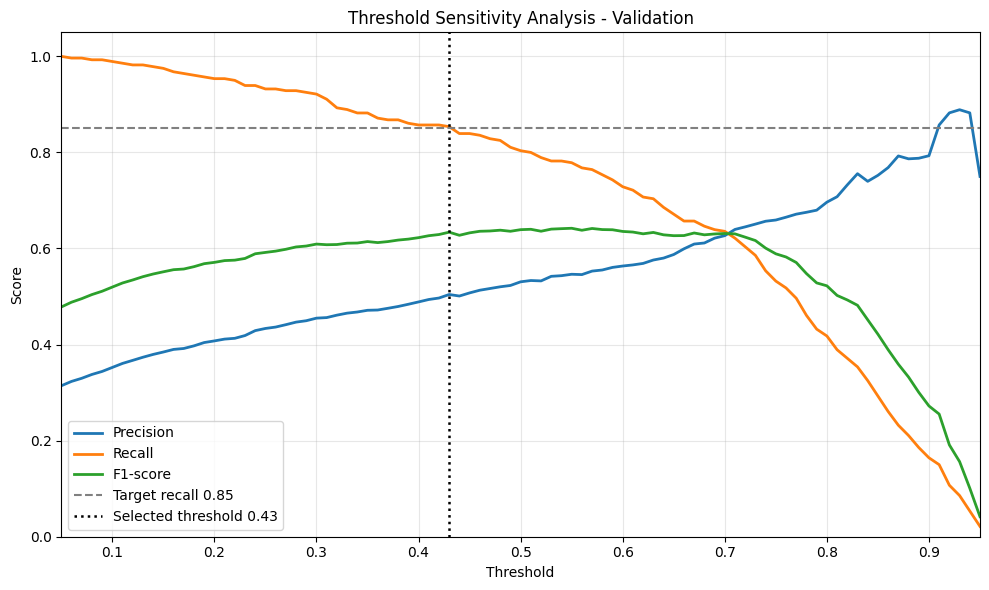

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/logistic_02_threshold_sensitivity_validation.png')

In [9]:
threshold_sensitivity_validation = scan_thresholds(
    y_true=y_val,
    y_proba=validation_proba,
    thresholds=THRESHOLDS,
    target_recall=TARGET_RECALL,
)
display_and_save_table(
    threshold_sensitivity_validation,
    'logistic_threshold_sensitivity_validation.csv',
    'Threshold Sensitivity Analysis on validation data',
)

selected_threshold, selected_threshold_validation_metrics = select_threshold(
    threshold_sensitivity_validation,
    target_recall=TARGET_RECALL,
)
display_and_save_table(
    selected_threshold_validation_metrics,
    'logistic_selected_threshold_validation_metrics.csv',
    'Selected threshold validation metrics',
)

validation_pred_selected = (validation_proba >= selected_threshold).astype(int)

selected_validation_confusion_matrix = build_confusion_matrix_table(
    y_true=y_val,
    y_pred=validation_pred_selected,
    split_name='validation',
    threshold=selected_threshold,
)
display_and_save_table(
    selected_validation_confusion_matrix,
    'logistic_selected_threshold_validation_confusion_matrix.csv',
    'Validation confusion matrix table at selected threshold',
)

selected_validation_classification_report = build_classification_report_table(
    y_true=y_val,
    y_pred=validation_pred_selected,
    split_name='validation',
    threshold=selected_threshold,
)
display_and_save_table(
    selected_validation_classification_report,
    'logistic_selected_threshold_validation_classification_report.csv',
    'Validation classification report at selected threshold',
)

print('Selected threshold from validation only:', selected_threshold)
print('Selected-threshold validation classification report:')
print(classification_report(y_val, validation_pred_selected, zero_division=0))

plot_threshold_sensitivity(threshold_sensitivity_validation, selected_threshold)
save_current_figure('logistic_02_threshold_sensitivity_validation.png')


## 10. Validation ROC and Precision-Recall Curves

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\logistic_03_roc_curve_validation.png


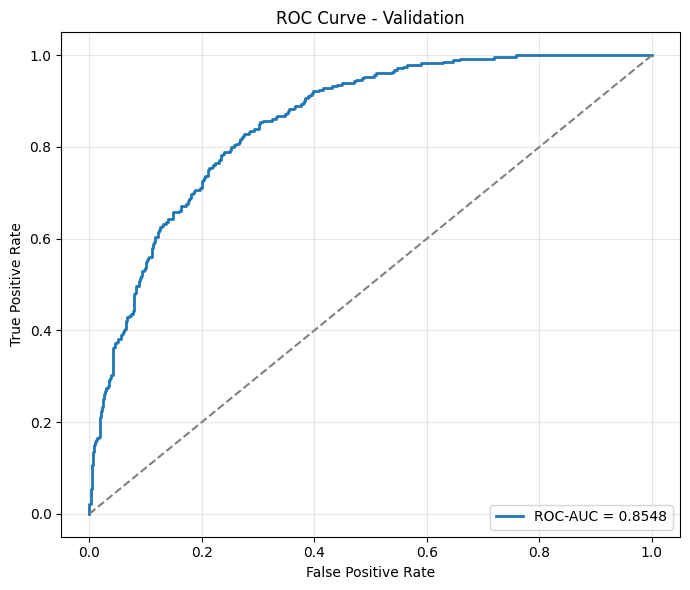

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\logistic_04_precision_recall_curve_validation.png


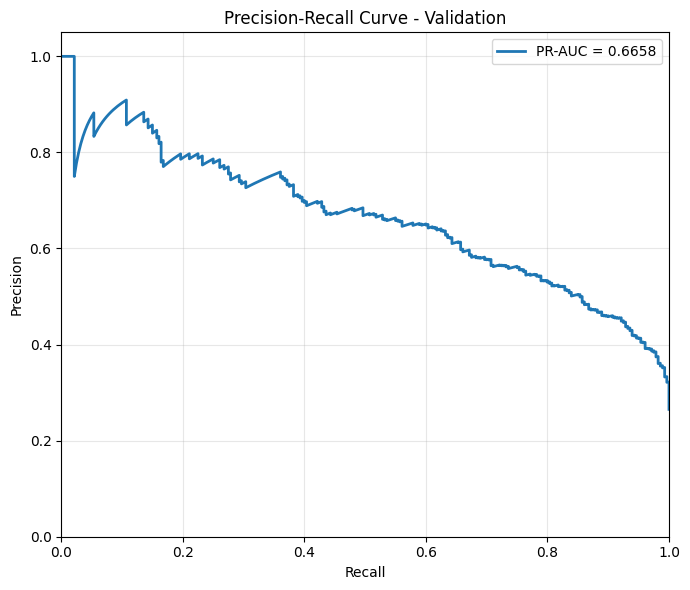

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/logistic_04_precision_recall_curve_validation.png')

In [10]:
plot_roc_curve(y_val, validation_proba)
save_current_figure('logistic_03_roc_curve_validation.png')

plot_precision_recall_curve(y_val, validation_proba)
save_current_figure('logistic_04_precision_recall_curve_validation.png')


## 11. Final Test Evaluation Using Selected Threshold

Final test metrics using validation-selected threshold


,Model,Split,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC,TP,FP,TN,FN,False_Positive_Rate,False_Negative_Rate,Threshold_Source
0,Logistic Regression,test,0.43,0.729423,0.494845,0.854093,0.626632,0.850811,0.663918,240,245,531,41,0.315722,0.145907,validation


Table shape: (1, 16)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\logistic_selected_threshold_test_metrics.csv
Final test confusion matrix table using validation-selected threshold


,Split,Threshold,Actual,Predicted,Count
0,test,0.43,0,0,531
1,test,0.43,0,1,245
2,test,0.43,1,0,41
3,test,0.43,1,1,240


Table shape: (4, 5)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\logistic_selected_threshold_test_confusion_matrix.csv
Final test classification report using validation-selected threshold


,Split,Threshold,Class,precision,recall,f1-score,support
0,test,0.43,0,0.928322,0.684278,0.787834,776.000000
1,test,0.43,1,0.494845,0.854093,0.626632,281.000000
2,test,0.43,accuracy,0.729423,0.729423,0.729423,0.729423
3,test,0.43,macro avg,0.711584,0.769185,0.707233,1057.000000
4,test,0.43,weighted avg,0.813083,0.729423,0.744979,1057.000000


Table shape: (5, 7)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\logistic_selected_threshold_test_classification_report.csv
Final test classification report using validation-selected threshold:
              precision    recall  f1-score   support

           0       0.93      0.68      0.79       776
           1       0.49      0.85      0.63       281

    accuracy                           0.73      1057
   macro avg       0.71      0.77      0.71      1057
weighted avg       0.81      0.73      0.74      1057

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\logistic_05_test_confusion_matrix_selected_threshold.png


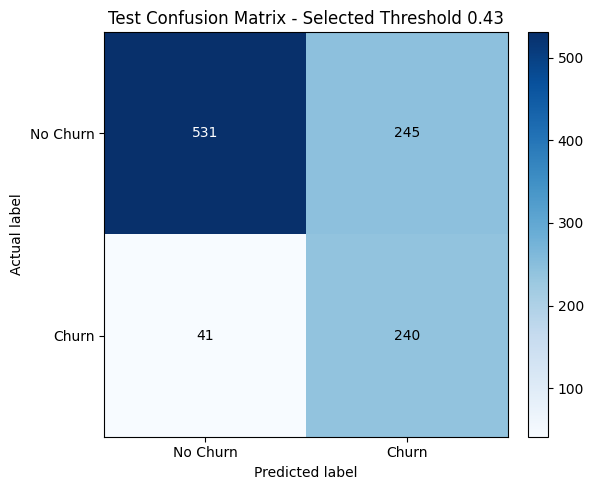

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/logistic_05_test_confusion_matrix_selected_threshold.png')

In [11]:
test_proba = logistic_model.predict_proba(X_test)[:, 1]
test_pred_selected = (test_proba >= selected_threshold).astype(int)

selected_threshold_test_metrics = evaluate_binary_classifier(
    y_true=y_test,
    y_proba=test_proba,
    threshold=selected_threshold,
    split_name='test',
)
selected_threshold_test_metrics['Threshold_Source'] = 'validation'
display_and_save_table(
    selected_threshold_test_metrics,
    'logistic_selected_threshold_test_metrics.csv',
    'Final test metrics using validation-selected threshold',
)

selected_test_confusion_matrix = build_confusion_matrix_table(
    y_true=y_test,
    y_pred=test_pred_selected,
    split_name='test',
    threshold=selected_threshold,
)
display_and_save_table(
    selected_test_confusion_matrix,
    'logistic_selected_threshold_test_confusion_matrix.csv',
    'Final test confusion matrix table using validation-selected threshold',
)

selected_test_classification_report = build_classification_report_table(
    y_true=y_test,
    y_pred=test_pred_selected,
    split_name='test',
    threshold=selected_threshold,
)
display_and_save_table(
    selected_test_classification_report,
    'logistic_selected_threshold_test_classification_report.csv',
    'Final test classification report using validation-selected threshold',
)

print('Final test classification report using validation-selected threshold:')
print(classification_report(y_test, test_pred_selected, zero_division=0))

plot_confusion_matrix_from_values(
    y_true=y_test,
    y_pred=test_pred_selected,
    title=f'Test Confusion Matrix - Selected Threshold {selected_threshold:.2f}',
)
save_current_figure('logistic_05_test_confusion_matrix_selected_threshold.png')


## 12. Coefficient Analysis

Logistic Regression coefficient table


,feature,coefficient,abs_coefficient,direction
0,TotalCharges,-0.766378,0.766378,decreases churn probability
1,Contract_24,-0.683150,0.683150,decreases churn probability
2,Dependents_Yes,-0.649922,0.649922,decreases churn probability
3,InternetService_No,-0.378273,0.378273,decreases churn probability
4,Contract_12,-0.336179,0.336179,decreases churn probability
5,monthly_charges_ratio,0.334798,0.334798,increases churn probability
6,MonthlyCharges,0.334798,0.334798,increases churn probability
7,PaperlessBilling_1,0.236857,0.236857,increases churn probability
8,Tenure,-0.208399,0.208399,decreases churn probability
9,InternetService_Fiber optic,0.159882,0.159882,increases churn probability


Table shape: (26, 4)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\logistic_coefficients.csv
Top positive coefficients


,feature,coefficient,abs_coefficient,direction
0,monthly_charges_ratio,0.334798,0.334798,increases churn probability
1,MonthlyCharges,0.334798,0.334798,increases churn probability
2,PaperlessBilling_1,0.236857,0.236857,increases churn probability
3,InternetService_Fiber optic,0.159882,0.159882,increases churn probability
4,Partner_1,0.125992,0.125992,increases churn probability
5,PaymentMethod_Electronic check,0.119856,0.119856,increases churn probability
6,tenure_group_37-48 months,0.082818,0.082818,increases churn probability
7,tenure_group_49-60 months,0.051353,0.051353,increases churn probability
8,SeniorCitizen,0.041368,0.041368,increases churn probability
9,tenure_group_61-72 months,0.032155,0.032155,increases churn probability


Table shape: (10, 4)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\logistic_top_positive_coefficients.csv
Top negative coefficients


,feature,coefficient,abs_coefficient,direction
0,TotalCharges,-0.766378,0.766378,decreases churn probability
1,Contract_24,-0.683150,0.683150,decreases churn probability
2,Dependents_Yes,-0.649922,0.649922,decreases churn probability
3,InternetService_No,-0.378273,0.378273,decreases churn probability
4,Contract_12,-0.336179,0.336179,decreases churn probability
5,Tenure,-0.208399,0.208399,decreases churn probability
6,TechSupport_1,-0.133703,0.133703,decreases churn probability
7,OnlineSecurity_1,-0.101476,0.101476,decreases churn probability
8,PaymentMethod_Mailed check,-0.097204,0.097204,decreases churn probability
9,service_diversity,-0.094843,0.094843,decreases churn probability


Table shape: (10, 4)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\logistic_top_negative_coefficients.csv
Top absolute coefficients


,feature,coefficient,abs_coefficient,direction
0,TotalCharges,-0.766378,0.766378,decreases churn probability
1,Contract_24,-0.683150,0.683150,decreases churn probability
2,Dependents_Yes,-0.649922,0.649922,decreases churn probability
3,InternetService_No,-0.378273,0.378273,decreases churn probability
4,Contract_12,-0.336179,0.336179,decreases churn probability
5,monthly_charges_ratio,0.334798,0.334798,increases churn probability
6,MonthlyCharges,0.334798,0.334798,increases churn probability
7,PaperlessBilling_1,0.236857,0.236857,increases churn probability
8,Tenure,-0.208399,0.208399,decreases churn probability
9,InternetService_Fiber optic,0.159882,0.159882,increases churn probability


Table shape: (15, 4)
Saved table: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\logistic_top_absolute_coefficients.csv
Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\logistic_06_top_positive_coefficients.png


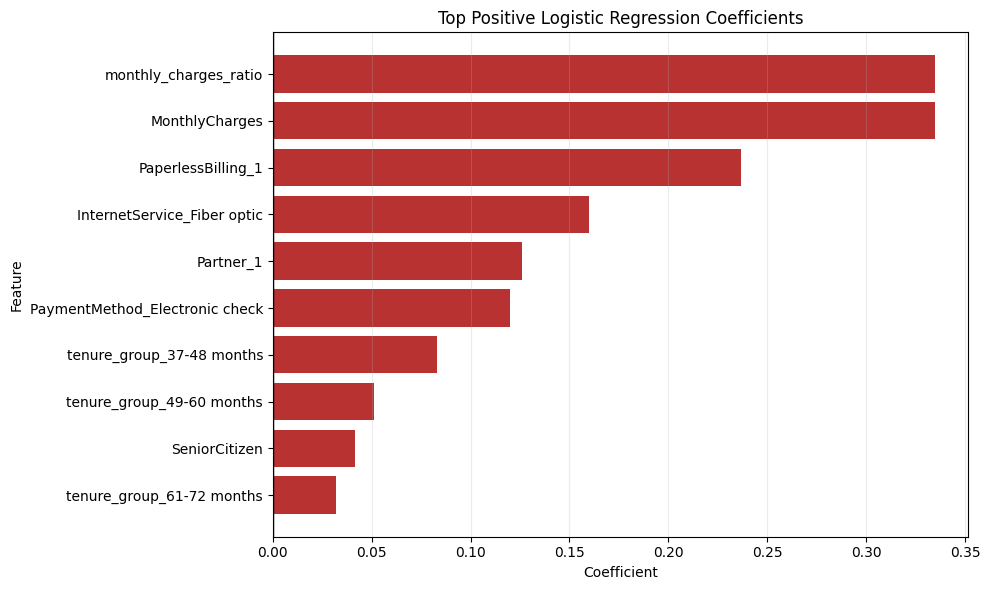

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\logistic_07_top_negative_coefficients.png


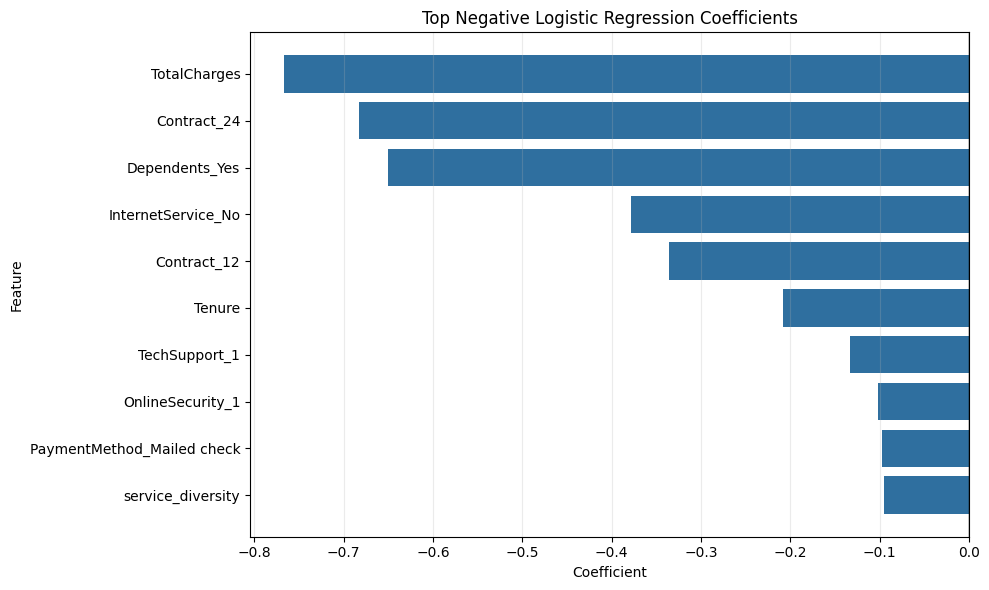

Saved figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\logistic_08_top_absolute_coefficients.png


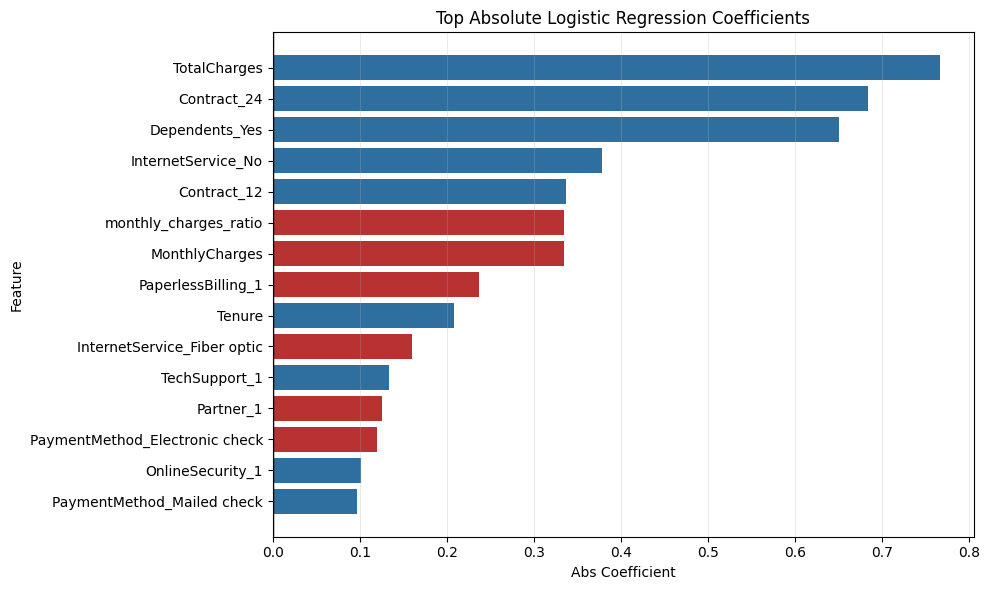

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/logistic_08_top_absolute_coefficients.png')

In [12]:
feature_name_mapping_reference = build_feature_reference_table()
display_and_save_table(
    feature_name_mapping_reference,
    'feature_name_mapping_reference.csv',
    'Canonical feature name mapping reference',
)

feature_name_mapping_logistic = build_feature_mapping_table(X_train.columns)
display_and_save_table(
    feature_name_mapping_logistic,
    'feature_name_mapping_logistic.csv',
    'Logistic Regression feature name mapping',
)

logistic_coefficients = build_coefficient_table(logistic_model, X_train.columns)
display_and_save_table(
    logistic_coefficients,
    'logistic_coefficients.csv',
    'Logistic Regression coefficient table',
)

logistic_top_positive_coefficients = (
    logistic_coefficients[logistic_coefficients['Coefficient'] > 0]
    .sort_values('Coefficient', ascending=False)
    .head(10)
    .reset_index(drop=True)
)
display_and_save_table(
    logistic_top_positive_coefficients,
    'logistic_top_positive_coefficients.csv',
    'Top positive coefficients',
)

logistic_top_negative_coefficients = (
    logistic_coefficients[logistic_coefficients['Coefficient'] < 0]
    .sort_values('Coefficient', ascending=True)
    .head(10)
    .reset_index(drop=True)
)
display_and_save_table(
    logistic_top_negative_coefficients,
    'logistic_top_negative_coefficients.csv',
    'Top negative coefficients',
)

logistic_top_absolute_coefficients = (
    logistic_coefficients.sort_values('Abs_Coefficient', ascending=False)
    .head(15)
    .reset_index(drop=True)
)
display_and_save_table(
    logistic_top_absolute_coefficients,
    'logistic_top_absolute_coefficients.csv',
    'Top absolute coefficients',
)

plot_coefficient_barh(
    logistic_top_positive_coefficients,
    'Top Positive Logistic Regression Coefficients',
)
save_current_figure('logistic_06_top_positive_coefficients.png')

plot_coefficient_barh(
    logistic_top_negative_coefficients,
    'Top Negative Logistic Regression Coefficients',
)
save_current_figure('logistic_07_top_negative_coefficients.png')

plot_coefficient_barh(
    logistic_top_absolute_coefficients,
    'Top Absolute Logistic Regression Coefficients',
    value_column='Abs_Coefficient',
)
save_current_figure('logistic_08_top_absolute_coefficients.png')


## 13. Final Notebook Summary

In [13]:
print('Notebook 2 Logistic Regression summary')
print('Pipeline call: run_pipeline(force_ingestion=False, use_database=False)')
print('Training branch used: outputs[\'logistic\'] only')
print('Logistic train shape:', logistic_train.shape)
print('Logistic validation shape:', logistic_val.shape)
print('Logistic test shape:', logistic_test.shape)
print('X_train shape:', X_train.shape)
print('X_val shape:', X_val.shape)
print('X_test shape:', X_test.shape)
print('Selected validation threshold:', selected_threshold)
print('Validation-selected threshold used for final test evaluation.')
print('CSV outputs directory:', DATA_REPORTS_DIR)
print('Figure outputs directory:', FIGURES_DIR)


Notebook 2 Logistic Regression summary
Pipeline call: run_pipeline(force_ingestion=False, use_database=False)
Training branch used: outputs['logistic'] only
Logistic train shape: (4930, 28)
Logistic validation shape: (1056, 28)
Logistic test shape: (1057, 28)
X_train shape: (4930, 26)
X_val shape: (1056, 26)
X_test shape: (1057, 26)
Selected validation threshold: 0.43
Validation-selected threshold used for final test evaluation.
CSV outputs directory: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports
Figure outputs directory: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures
